# Importação dos Dados



```
dados/                     
  ├── metadata.csv            # uma linha por áudio original
  ├── audios/                 # todos os áudios em WAV mono 16 kHz
  │   ├── P001_acender_luz_r1.wav        
  │   ├── P001_acender_luz_r2.wav
  │   ├── ...
  │   └── C0001_common_voice_pt_<id>.wav
  └── musan/
      └── noise/              # ruídos do MUSAN (só a parte "noise")
          ├── free-sound/
          └── sound-bible/
```


In [1]:
from google.colab import drive; drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/Projetos/Deteccao_Vozes/dados.zip -d /content

Mounted at /content/drive


# Treinamento da Baseline
Regressão logística sobre estatísticas de coeficientes cepstrais de Mel (MFCC),
com rejeição de previsões abaixo de um limiar escolhido exclusivamente na validação.

### Pipeline:
padronização -> divisão por locutor -> ruído por SNR -> MFCC -> treino -> limiar na validação

In [2]:
import os, glob, time, copy
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, log_loss

SEED = 42
SR, DUR = 16000, 2.0
N = int(SR * DUR)
SNRS = [20, 10, 0]
CONDS = ["limpo", "20dB", "10dB", "0dB"]
SEMENTES = [0, 1, 2]
RODAR_TESTE = False   # True só uma vez, no fim, junto com as CNNs
AUDIO_DIR, META = "dados/audios", "dados/metadata.csv"
NOISE_DIR, OUT = "dados/musan/noise", "saida"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)

## 1. Padronização

In [3]:
def carregar(caminho):
    y, _ = librosa.load(caminho, sr=SR, mono=True)          # mono, 16 kHz
    y, _ = librosa.effects.trim(y, top_db=30)               # tira silêncio das pontas
    if len(y) >= N:                                         # duração fixa de 2 s
        s = (len(y) - N) // 2
        y = y[s:s + N]
    else:
        pad = N - len(y)
        y = np.pad(y, (pad // 2, pad - pad // 2))
    return 0.9 * y / (np.max(np.abs(y)) + 1e-9)             # normaliza o pico

## 2. Divisão por Locutor

60% Treino, 20% Validação, 20% Teste

In [4]:
meta = pd.read_csv(META)
# Divide separadamente os locutores do grupo (comandos) e os do Common Voice (negativos),
# para que treino, validação e teste recebam as duas classes.
particao = {}
for _, grupo in meta.groupby("tipo"):
    locutores = np.array(sorted(grupo["locutor"].unique()))
    rng.shuffle(locutores)
    a, b = int(round(0.6 * len(locutores))), int(round(0.8 * len(locutores)))
    particao.update({l: "treino" for l in locutores[:a]})
    particao.update({l: "val" for l in locutores[a:b]})
    particao.update({l: "teste" for l in locutores[b:]})
meta["particao"] = meta["locutor"].map(particao)
meta.to_csv(f"{OUT}/divisao.csv", index=False)
print(meta.groupby(["particao", "tipo"]).agg(audios=("arquivo", "size"), locutores=("locutor", "nunique")))

                   audios  locutores
particao tipo                       
teste    comando      108          9
         negativo     104         40
treino   comando      312         26
         negativo     322        121
val      comando       96          8
         negativo      93         41


## 3. Ruídos divididos por Partição

In [5]:
ruidos = sorted(glob.glob(f"{NOISE_DIR}/**/*.wav", recursive=True))
if len(ruidos) < 5:
    raise FileNotFoundError(f"Poucos ruídos em {NOISE_DIR} ({len(ruidos)}). Baixe o MUSAN (ou só a parte 'noise') antes.")
rng.shuffle(ruidos)
k = len(ruidos)
ruidos_part = {"treino": ruidos[:int(0.6 * k)],
               "val": ruidos[int(0.6 * k):int(0.8 * k)],
               "teste": ruidos[int(0.8 * k):]}

def misturar(y, arquivo_ruido, snr_db):
    r, _ = librosa.load(arquivo_ruido, sr=SR, mono=True)
    if len(r) < N:
        r = np.tile(r, N // max(len(r), 1) + 1)
    s = rng.integers(0, len(r) - N + 1)
    r = r[s:s + N]
    voz = y[np.abs(y) > 0.02 * np.max(np.abs(y))]           # potência só do trecho com voz
    p_voz = np.mean(voz ** 2) if len(voz) else np.mean(y ** 2)  # evita NaN em áudio vazio
    p_ruido = np.mean(r ** 2) + 1e-12
    ganho = np.sqrt(p_voz / (p_ruido * 10 ** (snr_db / 10)))
    m = y + ganho * r
    return 0.9 * m / (np.max(np.abs(m)) + 1e-9)             # evita saturação

## 4. Aplicação do MFCC

In [6]:
def mfcc_stats(y):
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=400, hop_length=160)  # janelas 25 ms / 10 ms
    f = np.vstack([m, librosa.feature.delta(m)])
    return np.concatenate([f.mean(axis=1), f.std(axis=1)])   # vetor de 52 valores

linhas, X = [], []
for _, r in meta.iterrows():
    y = carregar(os.path.join(AUDIO_DIR, r["arquivo"]))
    base = r.to_dict()
    X.append(mfcc_stats(y)); linhas.append({**base, "cond": "limpo", "ruido": "", "snr": np.nan})
    for snr in SNRS:
        rz = rng.choice(ruidos_part[r["particao"]])
        X.append(mfcc_stats(misturar(y, rz, snr)))
        linhas.append({**base, "cond": f"{snr}dB", "ruido": os.path.basename(rz), "snr": snr})
df = pd.DataFrame(linhas)
X = np.array(X)
ok = np.isfinite(X).all(axis=1)                         # remove amostras com NaN/inf
if not ok.all():
    print(f"Removendo {(~ok).sum()} amostras com NaN/inf")
    X, df = X[ok], df[ok].reset_index(drop=True)
df.to_csv(f"{OUT}/registro_ruido.csv", index=False)       # qual ruído e SNR gerou cada amostra

## 5. Treinamento

Regressão logística sobre estatísticas de coeficientes cepstrais de Mel (MFCC)

In [7]:
tr = (df.particao == "treino") & (df.tipo == "comando")
va_cmd = (df.particao == "val") & (df.tipo == "comando")
va_neg = (df.particao == "val") & (df.tipo == "negativo")
classes = np.array(sorted(df.loc[tr, "rotulo"].unique()))

def treinar(seed, alpha=1e-4, epocas=60):
    sc = StandardScaler().fit(X[tr])
    clf = SGDClassifier(loss="log_loss", alpha=alpha, learning_rate="constant",
                    eta0=0.01, random_state=seed)
    Xtr, ytr = sc.transform(X[tr]), df.loc[tr, "rotulo"].values
    Xva, yva = sc.transform(X[va_cmd]), df.loc[va_cmd, "rotulo"].values
    curva, melhor, melhor_perda = [], None, np.inf
    r = np.random.default_rng(seed)
    for _ in range(epocas):
        idx = r.permutation(len(Xtr))
        clf.partial_fit(Xtr[idx], ytr[idx], classes=classes)
        p_va = log_loss(yva, clf.predict_proba(Xva), labels=classes)
        curva.append((log_loss(ytr, clf.predict_proba(Xtr), labels=classes), p_va))
        if p_va < melhor_perda:                         # parada antecipada: melhor época
            melhor_perda, melhor = p_va, copy.deepcopy(clf)
    return sc, melhor, np.array(curva), melhor_perda

## 6. Escolha do limiar e avaliação

In [8]:
def avaliar(sc, clf, limiar, mascara_cmd, mascara_neg):
    pc = clf.predict_proba(sc.transform(X[mascara_cmd]))
    pn = clf.predict_proba(sc.transform(X[mascara_neg]))
    pred = np.where(pc.max(1) >= limiar, classes[pc.argmax(1)], "rejeitado")
    f1 = f1_score(df.loc[mascara_cmd, "rotulo"], pred, labels=classes, average="macro", zero_division=0)
    fa = np.mean(pn.max(1) >= limiar)                       # falsa aceitação de falas inválidas
    fr = np.mean(pc.max(1) < limiar)                        # rejeição de comandos válidos
    return f1, fa, fr

def escolher_limiar(sc, clf):
    # critério: minimizar FA + FR na validação, todas as condições juntas
    grade = np.linspace(0.2, 0.99, 80)
    custo = [sum(avaliar(sc, clf, t, va_cmd, va_neg)[1:]) for t in grade]
    return grade[int(np.argmin(custo))]

## 7. Execução

             logloss_val        macroF1            FA            FR         \
                    mean    std    mean    std   mean    std   mean    std   
alpha  cond                                                                  
0.0001 0dB         1.470  0.010   0.157  0.030  0.143  0.050  0.774  0.060   
       10dB        1.470  0.010   0.194  0.035  0.208  0.076  0.774  0.073   
       20dB        1.470  0.010   0.296  0.045  0.283  0.126  0.656  0.075   
       limpo       1.470  0.010   0.288  0.063  0.323  0.132  0.649  0.111   
0.0010 0dB         1.469  0.009   0.152  0.025  0.136  0.062  0.781  0.054   
       10dB        1.469  0.009   0.184  0.043  0.208  0.076  0.781  0.079   
       20dB        1.469  0.009   0.294  0.038  0.280  0.124  0.667  0.085   
       limpo       1.469  0.009   0.289  0.064  0.319  0.128  0.656  0.106   
0.0100 0dB         1.439  0.009   0.223  0.089  0.258  0.156  0.618  0.188   
       10dB        1.439  0.009   0.311  0.088  0.384  0.185  0.

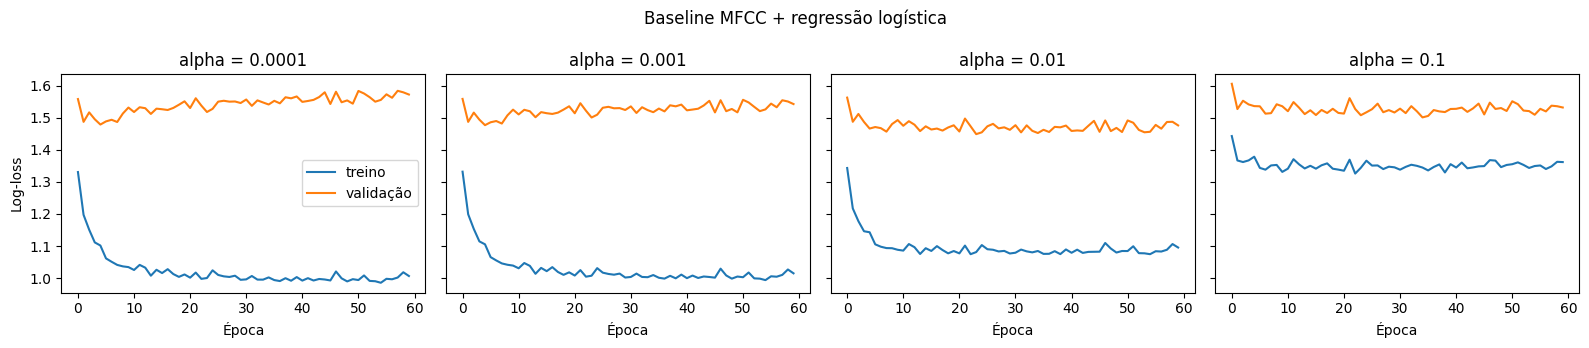

In [9]:
ALPHAS = [1e-4, 1e-3, 1e-2, 1e-1]

resultados = []
fig, eixos = plt.subplots(1, len(ALPHAS), figsize=(4 * len(ALPHAS), 3.5), sharey=True)

for j, alpha in enumerate(ALPHAS):
    for i, seed in enumerate(SEMENTES):
        t0 = time.time()
        sc, clf, curva, perda_val = treinar(seed, alpha)
        lim = escolher_limiar(sc, clf)
        tempo = time.time() - t0
        for cond in CONDS:
            c = (df.cond == cond).values
            f1, fa, fr = avaliar(sc, clf, lim, va_cmd & c, va_neg & c)
            resultados.append(dict(alpha=alpha, seed=seed, cond=cond, limiar=lim,
                                   logloss_val=perda_val, macroF1=f1, FA=fa, FR=fr, tempo_s=tempo))
        if i == 0:                               # curva da primeira semente de cada alpha
            ax = eixos[j]
            ax.plot(curva[:, 0], label="treino"); ax.plot(curva[:, 1], label="validação")
            ax.set_title(f"alpha = {alpha:g}"); ax.set_xlabel("Época")
    eixos[0].set_ylabel("Log-loss"); eixos[0].legend()

fig.suptitle("Baseline MFCC + regressão logística")
fig.tight_layout(); fig.savefig(f"{OUT}/curvas_alpha.png", dpi=200)

res = pd.DataFrame(resultados)
res.to_csv(f"{OUT}/resultados_val_alpha.csv", index=False)

resumo = (res.groupby(["alpha", "cond"])[["logloss_val", "macroF1", "FA", "FR", "tempo_s"]]
             .agg(["mean", "std"]))
print(resumo.round(3))

# Escolha do alpha: menor log-loss média de validação (só comandos)
ALPHA = res.groupby("alpha")["logloss_val"].mean().idxmin()
print(f"\nalpha escolhido na validação: {ALPHA:g}")

## 8. Resultados finais do baseline

Com o `alpha` escolhido, o baseline é treinado com as 3 sementes e avaliado por condição. As saídas seguem o mesmo formato das CNNs:

- `resultados_baseline.csv`: macro-F1, FA e FR por modelo, semente, partição e condição;
- `probabilidades_baseline.csv`: probabilidade de cada classe para cada amostra (para a curva FA × FR).

O teste só é avaliado com `RODAR_TESTE = True`, uma única vez, no fim.

In [10]:
def mascara(part, tipo, cond=None):
    m = (df["particao"] == part) & (df["tipo"] == tipo)
    if cond: m &= df["cond"] == cond
    return m.values

particoes = ["val", "teste"] if RODAR_TESTE else ["val"]
finais, probs = [], []
for seed in SEMENTES:
    t0 = time.time()
    sc, clf, _, _ = treinar(seed, ALPHA)
    lim = escolher_limiar(sc, clf)
    tempo = time.time() - t0
    for part in particoes:
        for cond in CONDS:
            f1, fa, fr = avaliar(sc, clf, lim, mascara(part, "comando", cond), mascara(part, "negativo", cond))
            finais.append(dict(modelo="Baseline", semente=seed, particao=part, cond=cond, limiar=lim,
                               macroF1=f1, FA=fa, FR=fr, tempo_treino_s=tempo))
        m = (df["particao"] == part).values
        tab = df.loc[m, ["arquivo", "locutor", "rotulo", "tipo", "particao", "cond"]].copy()
        tab[[f"p_{c}" for c in classes]] = clf.predict_proba(sc.transform(X[m]))
        tab["modelo"], tab["semente"], tab["limiar"] = "Baseline", seed, lim
        probs.append(tab)

res_final = pd.DataFrame(finais)
res_final.to_csv(f"{OUT}/resultados_baseline.csv", index=False)
pd.concat(probs).to_csv(f"{OUT}/probabilidades_baseline.csv", index=False)

for part in particoes:
    print(f"\nBaseline ({part}), média ± desvio em {len(SEMENTES)} sementes, alpha = {ALPHA:g}")
    print(res_final[res_final.particao == part].groupby("cond")[["macroF1", "FA", "FR"]]
          .agg(["mean", "std"]).reindex(CONDS).round(3))


Baseline (val), média ± desvio em 3 sementes, alpha = 0.01
      macroF1            FA            FR       
         mean    std   mean    std   mean    std
cond                                            
limpo   0.399  0.096  0.484  0.236  0.441  0.219
20dB    0.332  0.085  0.509  0.252  0.497  0.196
10dB    0.311  0.088  0.384  0.185  0.566  0.214
0dB     0.223  0.089  0.258  0.156  0.618  0.188


# Resultado do M2 (histórico, 14 participantes)
O teste inicial apresentou um resultado que era esperado com as médias da F1 caindo conforme o ruído aumentava, para o teste baseline utilizando regressão logística e escolhendo o limiar na validação após treinamento somente com comandos os resultados estão mostrados nas figuras abaixo:

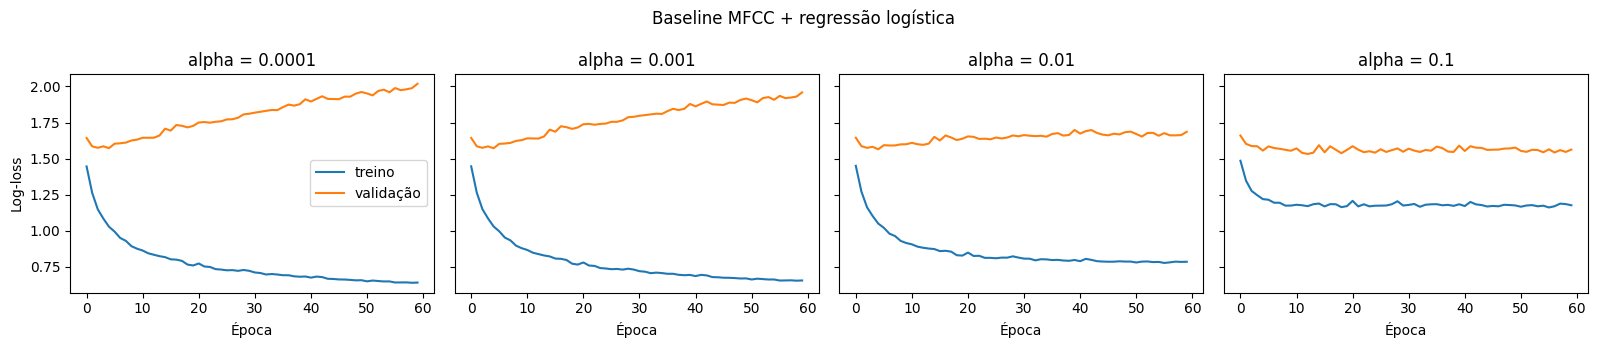

## Análise dos resultados
Para entendermos os resultados primeiro analisamos os gráficos gerados após o treinamento, visivelmente para os alphas menores houve overfitting e o modelo não generalizou, percebemos isso pela distanciação das curvas de treino e validação quanto a sua perda, o motivo desse overfitting vem do conjunto de dados que utilizamos momentaneamente:
```
audios   locutores   particao    tipo                       
teste    comando       36          3
         negativo      33         11
treino   comando       96          8
         negativo      99         33
val      comando       36          3
         negativo      33         11
```
Como estamos criando um dataset praticamente do zero e com pouco tempo, não conseguimos coletar um grande numero de vozes diferentes para cada um dos comandos, problema esse que com o prazo maior para a entrega do M3 poderá ser resolvido.
Por fim, na entrega final do projeto esperamos conseguir resultados mais conclusivos sobre o modelo, refazer o teste da baseline com mais locutores a fim de melhor ajustar o modelo aos diferentes conjuntos e, em seguida, desenvolver 2 modelos baseados em CNN, um deles trabalhando de acordo com o limiar, semelhante ao baseline, e outro modelo trabalhando com as classes negativas para medir o real impacto das duas abordagens.

In [11]:
DESTINO = "/content/drive/MyDrive/Projetos/Deteccao_Vozes"
NOME = "saida_baseline"

!cp -r /content/saida/ "$DESTINO/$NOME"
!ls "$DESTINO"

common-voice  dados.zip  figuras_ml  musan  saida_baseline  saida_ml
